<a href="https://colab.research.google.com/github/kavy988/ai-ml-dl-learning/blob/main/deep-learning/03_pytorch_computer_vision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### convolutional neural network ?

* is a specialized deep learning model designed for processing structured grid-like data, such as images, by mimicking the human visual system .

The key parts of CNN:

* Conv layer → scans for patterns
* Pooling layer → shrinks the image down
* Linear layer → makes final prediction

## 0. computer vision libaries in pytorch

* `torchvision` - base domain library for pytorch computer vision .

* `torchvision.datasets` - get datasets anda data loading functions for computer vision

* `torchvision.models` - get pretrained computer vision models that u can leverage for ur own problems

* `torchvision.transforms` - fucntions for manipulating ur vision data (images) to be suitable for use with an ML model

* `torch.utils.data.Dataset` -  base dataset class for pytorch .

* `torch.utils.data.Dataloader` - creates a python iterable over a dataset



torch vision - https://docs.pytorch.org/vision/stable/index.html

In [1]:
# import pytorch
import torch
from torch import nn

# import torchvision
import torchvision
from torchvision import datasets
from torchvision import transforms
from torchvision.transforms import ToTensor

# import matplotlb for visualization
import matplotlib.pyplot as plt
# check version
print(torch.__version__)
print(torchvision.__version__)

2.11.0+cpu
0.26.0+cpu


## 1. getting a dataset

the dataset we gonna be using is `FashionMNIST` - from torchvision.datasets

In [2]:
# setup training data
from torchvision import datasets
train_data = datasets.FashionMNIST(
    root ="data" , # where to download data to?
    train = True, # do we want the training dataset ?
    download = True, # do we want to download yes/ no ?
    transform  = ToTensor(), # how do we want to transform the data ?
    target_transform= None # how do  we want to transform the labels/ target ?
)

test_data  = datasets.FashionMNIST(
    root = "data",
    train = False ,
    download = True,
    transform = ToTensor(),
    target_transform= None
)

100%|██████████| 26.4M/26.4M [00:01<00:00, 18.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 266kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.06MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 19.5MB/s]


In [3]:
len(train_data) , len(test_data)

(60000, 10000)

In [4]:
# see the first training example
image, label = train_data[0]
image , label

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000, 0.0039, 

* .classes returns a list of all class names in the dataset!

In [5]:
class_names = train_data.classes
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

* .class_to_idx returns a dictionary mapping class names to numbers!

In [6]:
class_to_idx = train_data.class_to_idx
class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

In [7]:
train_data.targets

tensor([9, 0, 0,  ..., 3, 0, 5])

In [8]:
# check the shape of our image
print(f" image shape : {image.shape}  -> [color_channels , height  width]" )
print(f"image label : {class_names[label]} ")

 image shape : torch.Size([1, 28, 28])  -> [color_channels , height  width]
image label : Ankle boot 


### 1.2 visualizing tour data

plt.imshow() displays data as an image — it takes a 2D (or 3D) array of numbers and renders each value as a colored pixel/cell on a grid.

 image shape : torch.Size([1, 28, 28]) 


Text(0.5, 1.0, 'ankel boot')

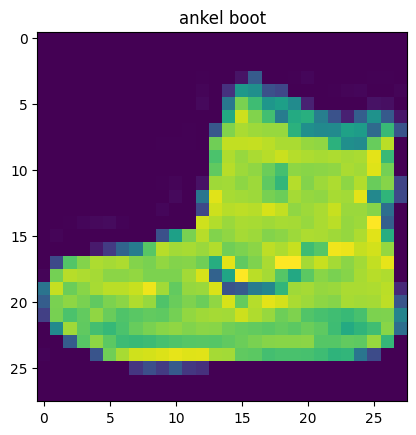

In [9]:
import matplotlib.pyplot as plt
image , label = train_data[0]
print(f" image shape : {image.shape} ")

plt.imshow(image.squeeze()) # what squeeze does it removes the singular dimension
plt.title("ankel boot")
#image

* plt.axis(True) → show the numbers (0, 5, 10, 15, 20, 25) on the sides ✅
* plt.axis(False) → hide the numbers — cleaner looking image!

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

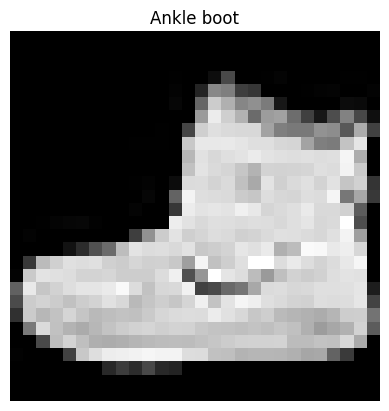

In [10]:
plt.imshow(image.squeeze() , cmap = "gray") # cmap for changing the colors of ur plot or a cmap property or paramter
plt.title(class_names[label]  );
plt.axis(False)

In [11]:
# Without item()
# torch.randint(0, 10, size=[1])
# → tensor([7])  ← still a tensor!

# With item()
# torch.randint(0, 10, size=[1]).item()
# → 7  ← plain Python number!

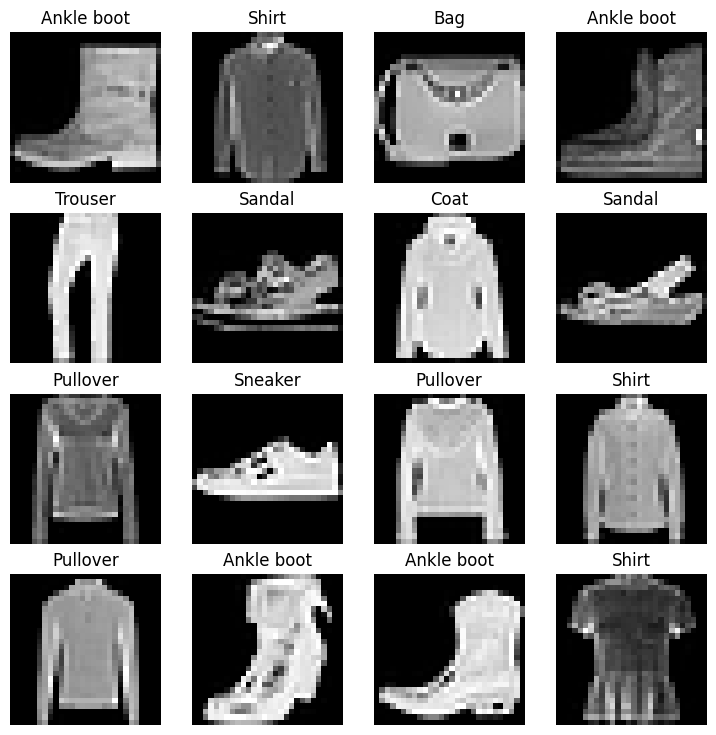

In [12]:
# plot more images
torch.manual_seed(42)
fig = plt.figure(figsize = (9,9))
rows , cols = 4, 4
for i in range(1, rows*cols+1): # here the rows*cols will create 16 images plot but like because we using the range function it will only go till 1 , 16 which means 15 photos
# so to create 16 images we did rows*cols+1
  random_idx = torch.randint(0 , len(train_data) , size = [1]).item()
  img, label = train_data[random_idx]
  fig.add_subplot(rows, cols, i)# diff b/w subplot and add_subplot - it wil create one display window for all and will add all the values to it like a grid
  plt.imshow(img.squeeze() , cmap = "gray")
  plt.title(class_names[label])
  plt.axis(False)


do u think these items of clothing (images) could be modelled with pure linear lines ? or do u think we will need non -linearities ?


In [13]:
train_data , test_data

(Dataset FashionMNIST
     Number of datapoints: 60000
     Root location: data
     Split: Train
     StandardTransform
 Transform: ToTensor(),
 Dataset FashionMNIST
     Number of datapoints: 10000
     Root location: data
     Split: Test
     StandardTransform
 Transform: ToTensor())

## 2. prepare dataloader

* right now , our data is in the form of pytorch datasets

* DataLoader turns our dataset into a python iterable

* more  specifically , we want to turn our data into baches (or mini batches )

* why would we do that ?

1.  it is more computationally efficient , as in , ur computing hardware may not be able to look (store im memory) at 6 k images in one hit . so we break it down to 32 images at a time (batch size of 32) .

2. it gives our neural network more chances to update its gradient per epoch .

one video from yt its the mini batches explaination - https://www.youtube.com/watch?v=ed4whd9B-xw&t=5s

read torch.utils.data - https://docs.pytorch.org/docs/stable/data.html

In [14]:
from torch.utils.data import DataLoader

# setup the batch size hyperparameter
BATCH_SIZE = 32

# turn dataset into interables
train_dataloader = DataLoader(dataset = train_data,
                              batch_size = BATCH_SIZE,
                              shuffle = True)

test_dataloader = DataLoader(dataset= test_data,
                             batch_size = BATCH_SIZE,
                             shuffle = False)

train_dataloader , test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x7c6d12ab6270>,
 <torch.utils.data.dataloader.DataLoader at 0x7c6d0bd66e90>)

In [15]:
# lets check out what we created
print(f" dataloader : {train_dataloader} , {test_dataloader}")
print(f" length of train_dataloader: {len(train_dataloader)} batches of {BATCH_SIZE}...  ")
print(f" length of test_dataloader : {len(test_dataloader)} batches of {BATCH_SIZE}....")

 dataloader : <torch.utils.data.dataloader.DataLoader object at 0x7c6d12ab6270> , <torch.utils.data.dataloader.DataLoader object at 0x7c6d0bd66e90>
 length of train_dataloader: 1875 batches of 32...  
 length of test_dataloader : 313 batches of 32....


* iter(train_dataloader)

1. converts the dataloader into an iterator
2. Think of it like opening a book to start reading

* next(...)

1. gets the next batch from the iterator
2. Like turning to the next page of the book

In [16]:
# check out what is inisde the training dataloader
train_features_batch , train_labels_batch = next(iter(train_dataloader))
train_features_batch.shape , train_labels_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

image size : torch.Size([1, 28, 28])
Lable : 6 , label size: torch.Size([])


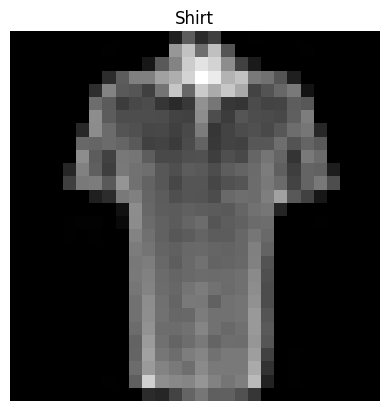

In [17]:
# show a sample
torch.manual_seed(42)
random_idx = torch.randint( 0 , len(train_features_batch) , size = [1]).item()
img , label = train_features_batch[random_idx], train_labels_batch[random_idx]
plt.imshow(img.squeeze(), cmap ="gray" )
plt.title(class_names[label] )
plt.axis (False)
print(f"image size : {img.shape}")
print(f"Lable : {label} , label size: {label.shape}")

## 3. model 0 building model

when starting to build  a series of machine learning modelling experiments , its best practice to start with a baseline model.

a baseline model is a simple model u will try and improve upon with subsequent models /experiments.
in other words: start simply and add complexity when necesssary

`nn.Flatten()` **squishes everything into one long line**

1. Imagine a Rubik's cube 🧩

* Before: numbers arranged in a 3D cube
* After: same numbers, but laid out in a single straight line

-> The values don't change, only the shape/arrangement changes!

In [18]:
# create a flatten layer
flatten_model = nn.Flatten()

# get a single saample
x = train_features_batch[0] # it means the first image of the batch comprises of 32 images and train_features_batch means first batch of train_dataloader

# flatten the sample
output = flatten_model(x) # perform forward pass

#  print  out ehat is happening
print(f"shape before flattening : {x.shape} -> [color_channels, height, weight]")
print(f"shape  after flattening : {output.shape} -> [color_channels, height, weight]  ")



shape before flattening : torch.Size([1, 28, 28]) -> [color_channels, height, weight]
shape  after flattening : torch.Size([1, 784]) -> [color_channels, height, weight]  


note ->
* nn.Sequential()
It's basically a pipeline 🚰 — you stack layers in order, and data flows through them one by one, top to bottom.

In [19]:
from torch import nn
class FashionMNISTModelV0(nn.Module):
  def __init__(self,
               input_shape: int,
               hidden_units: int,
               output_shape: int):
    super().__init__()
    self.layer_stack  = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=input_shape,
                  out_features= hidden_units),
        nn.Linear(in_features=hidden_units,
                  out_features=output_shape)
    )

  def forward(self, x):
    return self.layer_stack(x)


In [20]:
torch.manual_seed(42)

# setup model with input paramaeteres
model_0 = FashionMNISTModelV0(
    input_shape= 784 , # this is 28*28
    hidden_units =10, # how many units in the hidden layer
    output_shape = len(class_names) # one for every class
).to("cpu")

model_0

FashionMNISTModelV0(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)

In [21]:
dummy_x = torch.rand([1,1,28,28])
model_0(dummy_x)

tensor([[-0.0315,  0.3171,  0.0531, -0.2525,  0.5959,  0.2112,  0.3233,  0.2694,
         -0.1004,  0.0157]], grad_fn=<AddmmBackward0>)

In [22]:
model_0.state_dict()

OrderedDict([('layer_stack.1.weight',
              tensor([[ 0.0273,  0.0296, -0.0084,  ..., -0.0142,  0.0093,  0.0135],
                      [-0.0188, -0.0354,  0.0187,  ..., -0.0106, -0.0001,  0.0115],
                      [-0.0008,  0.0017,  0.0045,  ..., -0.0127, -0.0188,  0.0059],
                      ...,
                      [-0.0116,  0.0273, -0.0344,  ...,  0.0176,  0.0283, -0.0011],
                      [-0.0230,  0.0257,  0.0291,  ..., -0.0187, -0.0087,  0.0001],
                      [ 0.0176, -0.0147,  0.0053,  ..., -0.0336, -0.0221,  0.0205]])),
             ('layer_stack.1.bias',
              tensor([-0.0093,  0.0283, -0.0033,  0.0255,  0.0017,  0.0037, -0.0302, -0.0123,
                       0.0018,  0.0163])),
             ('layer_stack.2.weight',
              tensor([[ 0.0614, -0.0687,  0.0021,  0.2718,  0.2109,  0.1079, -0.2279, -0.1063,
                        0.2019,  0.2847],
                      [-0.1495,  0.1344, -0.0740,  0.2006, -0.0475, -0.2514, -0.

### 3.1 setup loss , optimizer and evaluation matrics

* loss function - since we are working with multi class data our loss fn will be `nn.CrossEntropyLoss()`

* optimizeer - our optimizer `torch.optim.SGD ()` - stochastic gradient descent   

* evalutation metric  - since we are working on a classification problem , lets see accuaracy as our evaluation metric  

In [23]:
import requests
from pathlib import Path

# download helper functions from pytorch repo
if Path(" helper_functions.py").is_file():
  print("helper_functions.py already exists , skipping download...")
else:
  print("Downloading helper_functions.py")
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/refs/heads/main/helper_functions.py")
  with open("helper_functions.py" , "wb") as f:
    f.write(request.content)


In [24]:
# import accuracy metric
from helper_functions import accuracy_fn

# setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params = model_0.parameters(),
                            lr = 0.1)


### creating a function to time our experice

machine learning is very experimental

two main things u often want to track

1. model's performance (loss and accuracy values etc)

2. how fast it runs


timer() - here is a function predefined for calculating the time

In [25]:
from timeit import default_timer as timer
def print_train_time(start: float,
                     end: float,
                     device: torch.device = None):
  """ prints difference between start and end time . """
  total_time = end - start
  print(f"train time on {device} : {total_time:.3f} seconds")
  return total_time


In [26]:
start_time = timer()
# some code...
end_time = timer()
print_train_time(start = start_time , end = end_time, device= "cpu")


train time on cpu : 0.000 seconds


6.665100005420754e-05

### 3.3 creating a training loop and training model on bactches of data
1. loop through epochs
2. loop through training batches , performs training steps , calculate the train loss *per batch*.
3. loop through testing batches ,perform testing steps , calculate the test loss per batch
4. print out whats happening
5. time it all (for fun)

check out this tqdm -  https://pypi.org/project/tqdm/

In [27]:
# enumerate() gives you both the index number and the value at the same time

In [28]:
# import tdqm for progress bar
from tqdm.auto import tqdm

# set the seed nd start the timer
torch.manual_seed(42)
train_time_start_on_cpu  = timer()

# set the number of epochs (we will keep this small for feaster training time )
epochs = 3


# create training and test loop
for epoch in tqdm(range(epochs)):
  print(f"Epoch : {epoch}\n------")
  ### training
  train_loss = 0
  # add a loop through the training batches
  for batch, (X, y) in enumerate(train_dataloader):
    model_0.train()
    # 1. forward pass
    y_pred = model_0(X)

    # 2. calclate loss (per batch)
    loss = loss_fn(y_pred, y)
    train_loss += loss # accumulate train loss

    # 3. optimizer zero grad
    optimizer.zero_grad()

    # 4. Loss backward
    loss.backward()

    # 5. optimizer step
    optimizer.step()

    # print out hwat is happening
    if batch % 400 == 0 :
      print(f" looked at {batch * len(X)}/{len(train_dataloader.dataset)} samples. ")

  # divide the total train loss by length of train dataloader
  train_loss /= len(train_dataloader)


  ### testing
  test_loss, test_acc= 0 , 0
  model_0.eval()
  with torch.inference_mode():
    for X_test, y_test in test_dataloader:
      # 1. forward pass
      test_pred = model_0(X_test)

      # 2. calculate the loss
      test_loss += loss_fn(test_pred, y_test)

      # 3. calc accuracy
      test_acc += accuracy_fn(y_true = y_test, y_pred = test_pred.argmax(dim = 1))

    # claculate the test loss average per batch
    test_loss /= len(test_dataloader)

    # calculate the test acc average per batch
    test_acc /=  len(test_dataloader)

  # print out what is happeing
  print(f"n train loss: {train_loss:.2f} | test loss : {test_loss:.4f},  test acc : {test_acc:.4f}")

# claculate training time
train_time_end_on_cpu = timer()
total_train_time_model_0 = print_train_time(start=train_time_start_on_cpu,
                                            end = train_time_end_on_cpu,
                                            device =str(next(model_0.parameters()).device))



  0%|          | 0/3 [00:00<?, ?it/s]

Epoch : 0
------
 looked at 0/60000 samples. 
 looked at 12800/60000 samples. 
 looked at 25600/60000 samples. 
 looked at 38400/60000 samples. 
 looked at 51200/60000 samples. 
n train loss: 0.59 | test loss : 0.5095,  test acc : 82.0387
Epoch : 1
------
 looked at 0/60000 samples. 
 looked at 12800/60000 samples. 
 looked at 25600/60000 samples. 
 looked at 38400/60000 samples. 
 looked at 51200/60000 samples. 
n train loss: 0.48 | test loss : 0.4799,  test acc : 83.1969
Epoch : 2
------
 looked at 0/60000 samples. 
 looked at 12800/60000 samples. 
 looked at 25600/60000 samples. 
 looked at 38400/60000 samples. 
 looked at 51200/60000 samples. 
n train loss: 0.46 | test loss : 0.4766,  test acc : 83.4265
train time on cpu : 30.686 seconds


In [29]:
next(model_0.parameters()).device

device(type='cpu')

## 4. make predictions and get model 0 results

In [30]:
torch.manual_seed(42)
def eval_model(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn : torch.nn.Module,
               accuracy_fn):
  """ returns  a dictionary containing the results pf model predictions on data_loader. """
  loss, acc = 0,0
  model.eval()
  with torch.inference_mode():
    for X , y in tqdm(data_loader):
      # make predictions
      y_pred  = model(X)

      # accumulate the loss and acc values per batch
      loss += loss_fn (y_pred, y)
      acc += accuracy_fn(y_true= y,
                         y_pred = y_pred.argmax(dim = 1))

    # scale loss and acc to find the average loss/acc per batch
    loss /= len(data_loader)
    acc /= len(data_loader)

  return {"model_name": model.__class__.__name__, # only works when model was created with class name
            "model_loss": loss.item(),
            "model_acc": acc }

# calculate model 0 results on test dataset
model_0_results = eval_model(model = model_0,
                            data_loader = test_dataloader,
                            loss_fn = loss_fn,
                            accuracy_fn = accuracy_fn)

model_0_results

  0%|          | 0/313 [00:00<?, ?it/s]

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47663894295692444,
 'model_acc': 83.42651757188499}

## 5. setup device agnostic- code(for using a gpu if there is one)

In [31]:
# setup device agnostic code
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"


## 6 . model 1 is building a better model wth non-linearity

we learned about the power of non linearity in notebook 2


In [32]:
# create a model with non linear and linear layers
class FashionMNISTModelV1(nn.Module):
  def __init__(self,
               input_shape: int,
               hidden_units: int,
               output_shape: int):
    super().__init__()
    self.layer_stack = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features = input_shape, out_features=hidden_units),
        nn.ReLU(),# relu layer wont change the shape our layer so dont worry
        nn.Linear(in_features=hidden_units, out_features= output_shape),
        nn.ReLU()
    )
  def forward(self, x: torch.Tensor):
    return self.layer_stack(x)


In [33]:
next(model_0.parameters()).device

device(type='cpu')

In [34]:
# create an instance of model_1
torch.manual_seed(42)
model_1 = FashionMNISTModelV1(input_shape = 784 , # this is output of this flatten after our 28*28 image goes in
                              hidden_units = 10,
                              output_shape = len(class_names)).to(device) # send to the gpu if its available
next(model_1.parameters()).device


device(type='cpu')

### 6.1 setup loss , optimizer and evalutaton metrics


In [35]:
from helper_functions import accuracy_fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params = model_1.parameters(),
                            lr =0.01)

### 6.2  functioning training and evaluation / testing loops
1. lets create a function fo r:
* training loop - `train_step()`
* testing loop - `test_step()`

In [36]:
def train_step(model:  torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.nn.Module,
               accuracy_fn,
               device: torch.device = device):
  """ perform  tarining with model trying to learn on data_loader """

  train_loss , train_acc = 0,0

  # put model into training mode
  model.train()

  # add a loop to loop through the training batches

  for batch, (X, y) in enumerate(data_loader):

    # put data on target device
    X, y = X.to(device), y.to(device)

    # 1. forward pass (outputs the raw logits from the modle)
    y_pred = model(X)

    # 2. calclate loss (per batch)
    loss = loss_fn(y_pred, y)
    train_loss += loss # accumulate train loss
    train_acc += accuracy_fn(y_true = y,
                             y_pred = y_pred.argmax(dim = 1)) # go from logits  -> prediction labels


    # 3. optimizer zero grad
    optimizer.zero_grad()

    # 4. Loss backward
    loss.backward()

    # 5. optimizer step
    optimizer.step()

    # print out hwat is happening
    if batch % 400 == 0 :
      print(f" looked at {batch * len(X)}/{len(train_dataloader.dataset)} samples. ")

  # divide the total train loss by length of train dataloader
  train_loss /= len(train_dataloader)
  train_acc /= len(train_dataloader)
  print(f"train loss : {train_loss: .5f} | train acc : {train_acc: .2f}% ")


In [37]:
def test_step(model: torch.nn.Module,
              data_loader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              accuracy_fn,
              device: torch.device = device):
  """ preforms a testing loop step on model going over data_loader. """

  test_loss, test_acc = 0,0

  # put the model in eval mode
  model.eval()

  # turn on inference mode context manager
  with torch.inference_mode():
    for X,y in data_loader:
      # send the data to the target device
      X, y = X.to(device), y.to(device)

      # forward pass
      test_pred = model(X)

      # calculate the loss/acc
      test_loss += loss_fn(test_pred , y)
      test_acc += accuracy_fn(y_true = y,
                              y_pred =test_pred.argmax(dim = 1))

    # adjust metrics and print out
    test_loss /= len(data_loader)
    test_acc /= len(data_loader)
    print(f" test loss : {test_loss : .5f} | test acc : {test_acc : .2f}%")



In [38]:
torch.manual_seed(42)

# measure time
from timeit import default_timer as timer
train_time_start_on_cpu = timer()

# set epochs
epochs = 3

# create a optimization and evaluation loop using train_step() and test_step()
for epoch in tqdm(range(epochs)):
  print(f"epoch : {epoch}\n------ ")
  train_step(model = model_1,
             data_loader = train_dataloader,
             loss_fn = loss_fn,
             optimizer = optimizer,
             accuracy_fn = accuracy_fn,
             device = device)

  test_step(model = model_1,
            data_loader = test_dataloader,
            loss_fn = loss_fn ,
            accuracy_fn = accuracy_fn,
            device = device
            )
train_time_end_on_cpu = timer()
total_train_time_model_1 = print_train_time(start = train_time_start_on_cpu,
                                            end= train_time_end_on_cpu,
                                            device = device)



  0%|          | 0/3 [00:00<?, ?it/s]

epoch : 0
------ 
 looked at 0/60000 samples. 
 looked at 12800/60000 samples. 
 looked at 25600/60000 samples. 
 looked at 38400/60000 samples. 
 looked at 51200/60000 samples. 
train loss :  1.42179 | train acc :  54.29% 
 test loss :  1.12168 | test acc :  62.15%
epoch : 1
------ 
 looked at 0/60000 samples. 
 looked at 12800/60000 samples. 
 looked at 25600/60000 samples. 
 looked at 38400/60000 samples. 
 looked at 51200/60000 samples. 
train loss :  1.03359 | train acc :  64.61% 
 test loss :  1.00019 | test acc :  64.48%
epoch : 2
------ 
 looked at 0/60000 samples. 
 looked at 12800/60000 samples. 
 looked at 25600/60000 samples. 
 looked at 38400/60000 samples. 
 looked at 51200/60000 samples. 
train loss :  0.95996 | train acc :  66.05% 
 test loss :  0.96338 | test acc :  65.41%
train time on cpu : 33.778 seconds


** Note **  sometimes , depending on your data/ hardware you might find thatt your model trains fastter on CPU than GPU

> why is this?

> 1. it could be that the overhead for copying data/model to and from the GPU outweights the compute benefits offered by the GPU .

>2. the hardware you are using has a better CPU in terms compute capabality then then GPU

https://horace.io/brrr_intro.html

> check this link vasu otherwise  to make your models faster



In [39]:
model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47663894295692444,
 'model_acc': 83.42651757188499}

In [40]:
total_train_time_model_1

33.77819934799999

# model 1

1. get model_1 results dicitionary



In [41]:
torch.manual_seed(42)
def eval_model(model: torch.nn.Module,
               data_loader : torch.utils.data.DataLoader,
               loss_fn : torch.nn.Module ,
               accuracy_fn ,
               device = device):
  loss , acc= 0,0
  model.eval()
  with torch.inference_mode():
    for X,y in tqdm(data_loader):
      # make our data device agnostic
      X,y = X.to(device) , y.to(device)

      # make predictions
      y_pred = model(X)

      # accumulate the loss and acc values per batch
      loss += loss_fn (y_pred , y)
      acc += accuracy_fn(y_true = y,
                         y_pred = y_pred.argmax(dim =1))

    # scale loss and acc to find the average loss/acc per batch
    loss /= len(data_loader)
    acc /= len(data_loader)


  return{"model_name" : model.__class__.__name__,
          "model_loss" : loss.item(),
          "model_acc" : acc}


In [42]:
model_1_results = eval_model(model = model_1,
                             data_loader = test_dataloader,
                             loss_fn = loss_fn,
                             accuracy_fn = accuracy_fn,
                             device =device)

model_1_results


  0%|          | 0/313 [00:00<?, ?it/s]

{'model_name': 'FashionMNISTModelV1',
 'model_loss': 0.9633837938308716,
 'model_acc': 65.40535143769968}

In [43]:
model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47663894295692444,
 'model_acc': 83.42651757188499}

# model 2 : Building a convolutional Neural Network (CNN)

(CNN 's are also known convNets)

CNN's are known for their capabalities to find pattern in visual data.



* check out a website called CNN explainer

* check out popular CNN architecture



In [44]:
# create a convolutional neural network
class FashionMNISTModelV2(nn.Module):
  """
  Model architecture that replicates the TinyVGG
  model from CNN explainer website.
  """
  def __init__(self,
               input_shape : int,
               hidden_units : int,
               output_shape : int):
    super().__init__()
    self.conv_block_1 = nn.Sequential(
        nn.Conv2d(in_channels = input_shape ,
                  out_channels = hidden_units,
                  kernel_size =3,
                  stride = 1,
                  padding = 1), # values that we can set outselves in our NN's are called hyperparameters
        nn.ReLU(),
        nn.Conv2d(in_channels = hidden_units ,
                  out_channels = hidden_units,
                  kernel_size = 3,
                  stride = 1,
                  padding = 1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2)
    )
    self.conv_block_2 = nn.Sequential(
        nn.Conv2d(in_channels = hidden_units,
                  out_channels = hidden_units,
                  kernel_size = 3 ,
                  stride = 1,
                  padding = 1),
        nn.ReLU(),
        nn.Conv2d(in_channels = hidden_units,
                  out_channels = hidden_units ,
                  kernel_size = 3,
                  stride = 1,
                  padding = 1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2)
    )
    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features = hidden_units*7*7 ,# there is a trick to calculate this
                  out_features = output_shape ,
                  )
    )
  def forward(self, x):
    x = self.conv_block_1(x)
    # print(f"Output shape of conv_block_1 : {x.shape}")
    x = self.conv_block_2(x)
    # print(f"output shape of conv_block_2 : {x.shape}")
    x = self.classifier(x)
    # print(f" output shape of classifier : {x.shape}")
    return x




In [45]:
torch.manual_seed(42)
model_2 = FashionMNISTModelV2(input_shape = 1,
                              hidden_units = 10,
                              output_shape = len(class_names)).to(device)


In [46]:
rand_image_tensor = torch.randn(size = (1,28,28))
rand_image_tensor.shape

torch.Size([1, 28, 28])

In [47]:
# pass image through model
model_2(rand_image_tensor.unsqueeze(0)).to(device)

tensor([[ 0.0366, -0.0940,  0.0686, -0.0485,  0.0068,  0.0290,  0.0132,  0.0084,
         -0.0030, -0.0185]], grad_fn=<AddmmBackward0>)

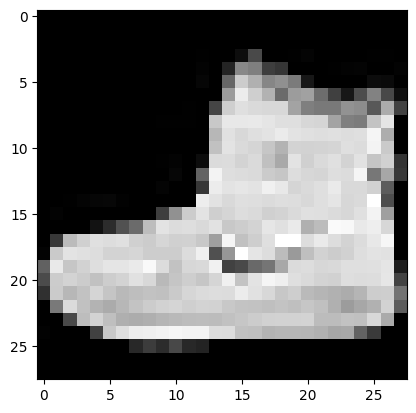

In [48]:
plt.imshow(image.squeeze() , cmap = "gray")

1. learn about conv2d

# 7.1 stepping through conv2d

In [49]:
torch.manual_seed(42)
# create a batch of images
images = torch.randn(size = (32, 3 , 64 , 64))
test_image = images[0]

print(f"image batch shape : {images.shape}")
print(f"single image shape : {test_image.shape}")
print(f"test image\n : {test_image}")

image batch shape : torch.Size([32, 3, 64, 64])
single image shape : torch.Size([3, 64, 64])
test image
 : tensor([[[ 1.9269,  1.4873,  0.9007,  ...,  1.8446, -1.1845,  1.3835],
         [ 1.4451,  0.8564,  2.2181,  ...,  0.3399,  0.7200,  0.4114],
         [ 1.9312,  1.0119, -1.4364,  ..., -0.5558,  0.7043,  0.7099],
         ...,
         [-0.5610, -0.4830,  0.4770,  ..., -0.2713, -0.9537, -0.6737],
         [ 0.3076, -0.1277,  0.0366,  ..., -2.0060,  0.2824, -0.8111],
         [-1.5486,  0.0485, -0.7712,  ..., -0.1403,  0.9416, -0.0118]],

        [[-0.5197,  1.8524,  1.8365,  ...,  0.8935, -1.5114, -0.8515],
         [ 2.0818,  1.0677, -1.4277,  ...,  1.6612, -2.6223, -0.4319],
         [-0.1010, -0.4388, -1.9775,  ...,  0.2106,  0.2536, -0.7318],
         ...,
         [ 0.2779,  0.7342, -0.3736,  ..., -0.4601,  0.1815,  0.1850],
         [ 0.7205, -0.2833,  0.0937,  ..., -0.1002, -2.3609,  2.2465],
         [-1.3242, -0.1973,  0.2920,  ...,  0.5409,  0.6940,  1.8563]],

        [

In [50]:
# create a single conv2d layer
torch.manual_seed(42)
conv_layer = nn.Conv2d(in_channels = 3,
                       out_channels = 10 ,
                       kernel_size = (3,3),
                       stride = 1,
                       padding = 1)
# pass the data through the convolutional layer
conv_output = conv_layer(test_image.unsqueeze(0))
conv_output.shape

torch.Size([1, 10, 64, 64])

In [51]:
test_image.unsqueeze(0).shape

torch.Size([1, 3, 64, 64])

In [52]:
torch.__version__

'2.11.0+cpu'

### 7.2 stepping through nn.MaxPool2d()

* here https://docs.pytorch.org/docs/2.12/generated/torch.nn.MaxPool2d.html

In [53]:
test_image

tensor([[[ 1.9269,  1.4873,  0.9007,  ...,  1.8446, -1.1845,  1.3835],
         [ 1.4451,  0.8564,  2.2181,  ...,  0.3399,  0.7200,  0.4114],
         [ 1.9312,  1.0119, -1.4364,  ..., -0.5558,  0.7043,  0.7099],
         ...,
         [-0.5610, -0.4830,  0.4770,  ..., -0.2713, -0.9537, -0.6737],
         [ 0.3076, -0.1277,  0.0366,  ..., -2.0060,  0.2824, -0.8111],
         [-1.5486,  0.0485, -0.7712,  ..., -0.1403,  0.9416, -0.0118]],

        [[-0.5197,  1.8524,  1.8365,  ...,  0.8935, -1.5114, -0.8515],
         [ 2.0818,  1.0677, -1.4277,  ...,  1.6612, -2.6223, -0.4319],
         [-0.1010, -0.4388, -1.9775,  ...,  0.2106,  0.2536, -0.7318],
         ...,
         [ 0.2779,  0.7342, -0.3736,  ..., -0.4601,  0.1815,  0.1850],
         [ 0.7205, -0.2833,  0.0937,  ..., -0.1002, -2.3609,  2.2465],
         [-1.3242, -0.1973,  0.2920,  ...,  0.5409,  0.6940,  1.8563]],

        [[-0.7978,  1.0261,  1.1465,  ...,  1.2134,  0.9354, -0.0780],
         [-1.4647, -1.9571,  0.1017,  ..., -1

In [54]:
# print out original image shape without unsqueezed dimension
print(f" Test image original shape: {test_image.shape}")
print(f"Test image with unsqueezed dimension : {test_image.unsqueeze(dim = 0).shape}")


# create a sample nn.MaxPool2d()
max_pool_layer = nn.MaxPool2d(kernel_size = 2)

# pass data through jsut the conv_layer
test_image_through_conv = conv_layer(test_image.unsqueeze(dim = 0))
print(f"shape after going through convo_layer(): {test_image_through_conv.shape}")

# pass data through the max pool layer
test_image_through_conv_and_max_pool = max_pool_layer(test_image_through_conv)
print(f"shape after going through conv_layer() and max_pool laye(): {test_image_through_conv_and_max_pool.shape}")

 Test image original shape: torch.Size([3, 64, 64])
Test image with unsqueezed dimension : torch.Size([1, 3, 64, 64])
shape after going through convo_layer(): torch.Size([1, 10, 64, 64])
shape after going through conv_layer() and max_pool laye(): torch.Size([1, 10, 32, 32])


In [55]:
torch.manual_seed(42)
# create a random tensor with a similar number of dimensions to our images
random_tensor = torch.randn(size = (1,1,2,2)) # (batch_size , color_channels , height, width)
print(f"\nrandom tensor :\n {random_tensor}")
print(f"\nrandom tensor shape :\n {random_tensor.shape}")


random tensor :
 tensor([[[[0.3367, 0.1288],
          [0.2345, 0.2303]]]])

random tensor shape :
 torch.Size([1, 1, 2, 2])


In [56]:
# creata a max pool layer
max_pool_layer= nn.MaxPool2d(kernel_size =2)

# pass the random tensor through the max pool layer
max_pool_tensor = max_pool_layer(random_tensor)
print(f"\n max pool tensor:\n {random_tensor}")
print(f"\n max pool tensor shape : {max_pool_tensor.shape}")
random_tensor


 max pool tensor:
 tensor([[[[0.3367, 0.1288],
          [0.2345, 0.2303]]]])

 max pool tensor shape : torch.Size([1, 1, 1, 1])


tensor([[[[0.3367, 0.1288],
          [0.2345, 0.2303]]]])

### 7.3 setup a loss function and optimizer for model_2

In [57]:
# setup loss function/eval metrics/optimizer

from helper_functions import accuracy_fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params = model_2.parameters(),
                            lr = 0.1)


### 7.4 trainign ans testing model_2 using our trainign and test functions

In [58]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# measure time
from timeit import default_timer as timer
train_time_start_model_2 = timer()

# train and test model
epochs =3
for epoch in tqdm(range(epochs)):
  print(f"epoch : {epoch}")
  train_step(model = model_2,
             data_loader = train_dataloader,
             loss_fn = loss_fn ,
             optimizer = optimizer ,
             accuracy_fn = accuracy_fn,
             device = device)
  test_step(model = model_2,
            data_loader = test_dataloader,
            loss_fn = loss_fn,
            accuracy_fn = accuracy_fn,
            device = device)

train_time_end_model_2  = timer()
total_train_time_model_2 = print_train_time(start = train_time_start_model_2,
                                            end = train_time_end_model_2,
                                            device =device)

  0%|          | 0/3 [00:00<?, ?it/s]

epoch : 0
 looked at 0/60000 samples. 
 looked at 12800/60000 samples. 
 looked at 25600/60000 samples. 
 looked at 38400/60000 samples. 
 looked at 51200/60000 samples. 
train loss :  0.59518 | train acc :  78.38% 
 test loss :  0.39500 | test acc :  85.99%
epoch : 1
 looked at 0/60000 samples. 
 looked at 12800/60000 samples. 
 looked at 25600/60000 samples. 
 looked at 38400/60000 samples. 
 looked at 51200/60000 samples. 
train loss :  0.36536 | train acc :  86.90% 
 test loss :  0.35244 | test acc :  86.91%
epoch : 2
 looked at 0/60000 samples. 
 looked at 12800/60000 samples. 
 looked at 25600/60000 samples. 
 looked at 38400/60000 samples. 
 looked at 51200/60000 samples. 
train loss :  0.32588 | train acc :  88.13% 
 test loss :  0.32719 | test acc :  88.07%
train time on cpu : 159.247 seconds


In [59]:
# get model_2 results
model_2_results = eval_model(
    model = model_2 ,
    data_loader = test_dataloader,
    loss_fn = loss_fn,
    accuracy_fn = accuracy_fn,
    device  = device
)

model_2_results

  0%|          | 0/313 [00:00<?, ?it/s]

{'model_name': 'FashionMNISTModelV2',
 'model_loss': 0.32718968391418457,
 'model_acc': 88.06908945686901}

## 8. compare model results and training time

In [60]:
import pandas as pd
compare_results = pd.DataFrame([model_0_results,
                               model_1_results,
                               model_2_results])

compare_results

,model_name,model_loss,model_acc
0,FashionMNISTModelV0,0.476639,83.426518
1,FashionMNISTModelV1,0.963384,65.405351
2,FashionMNISTModelV2,0.327190,88.069089


In [61]:
compare_results["training_time"] = [total_train_time_model_0,
                                    total_train_time_model_1,
                                    total_train_time_model_2]

compare_results

,model_name,model_loss,model_acc,training_time
0,FashionMNISTModelV0,0.476639,83.426518,30.685779
1,FashionMNISTModelV1,0.963384,65.405351,33.778199
2,FashionMNISTModelV2,0.327190,88.069089,159.247358


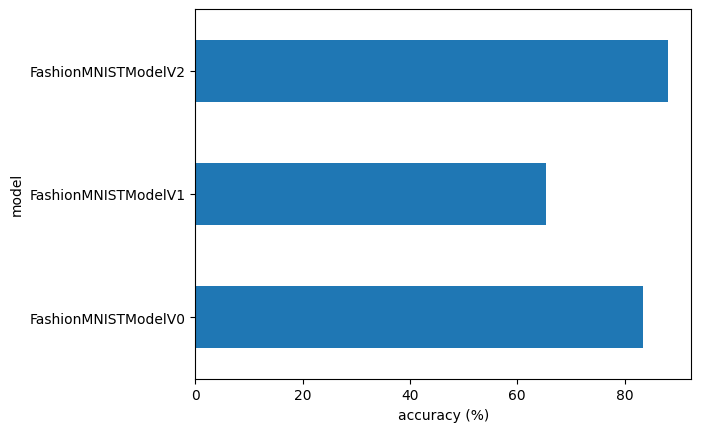

In [62]:
# visualize our model results
compare_results.set_index("model_name")["model_acc"].plot(kind = "barh")
plt.xlabel("accuracy (%)")
plt.ylabel("model");

## 9. make and evaluate random predictions with best model

In [63]:
def make_predictions(model: torch.nn.Module,
                      data : list,
                      device: torch.device = device):
  pred_probs = []
  model.to(device)
  model.eval()
  with torch.inference_mode():
    for sample in data:
      # prepare the sample (add a batch )
      sample = torch.unsqueeze(sample, dim = 0 ).to(device)

      # forward pass (model outputs raw logits)
      pred_logit  = model(sample)

      # get predictions probability (logit -> prediction probability )
      pred_prob = torch.softmax(pred_logit.squeeze(), dim = 0)

      # ge pred_prob off the gpu for further calculations
      pred_probs.append(pred_prob.cpu())

  # stack the pred_probs turn list into a tensor
  return torch.stack(pred_probs)


In [64]:
img , label = test_data[0][:10]
img.shape , label

(torch.Size([1, 28, 28]), 9)

In [65]:
import random
# random.seed(42)
test_samples = []
test_labels = []
for sample , label in random.sample(list(test_data), k = 9):
  test_samples.append(sample)
  test_labels.append(label)

# view the first sample shape
test_samples[0].shape


torch.Size([1, 28, 28])

Text(0.5, 1.0, 'Coat')

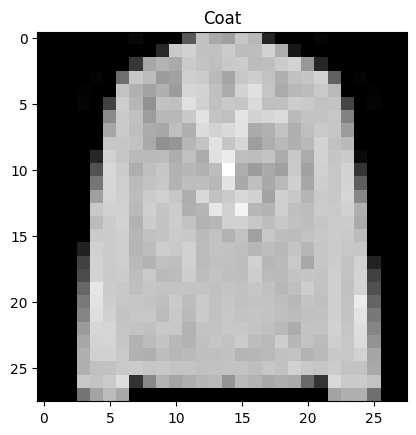

In [66]:
plt.imshow(test_samples[0].squeeze() , cmap = "gray")
plt.title(class_names[test_labels[0]])

In [67]:
# make predictions
pred_probs =  make_predictions(model= model_2,
                              data= test_samples)

# view the first two predictions probabilities
pred_probs[:2]

tensor([[4.5119e-03, 5.0867e-04, 3.1730e-02, 1.4246e-03, 7.1679e-01, 1.7579e-05,
         2.4256e-01, 5.2640e-05, 2.2251e-03, 1.7072e-04],
        [2.6355e-07, 1.3415e-07, 9.1868e-07, 7.4823e-07, 1.1858e-07, 9.9989e-01,
         1.1791e-07, 9.2897e-05, 1.4467e-05, 3.3844e-06]])

In [68]:
test_labels

[4, 5, 6, 3, 9, 8, 4, 5, 4]

In [69]:
# convert predictions probabilites to labels
pred_classes = pred_probs.argmax(dim = 1)
pred_classes

tensor([4, 5, 6, 3, 9, 8, 4, 5, 4])

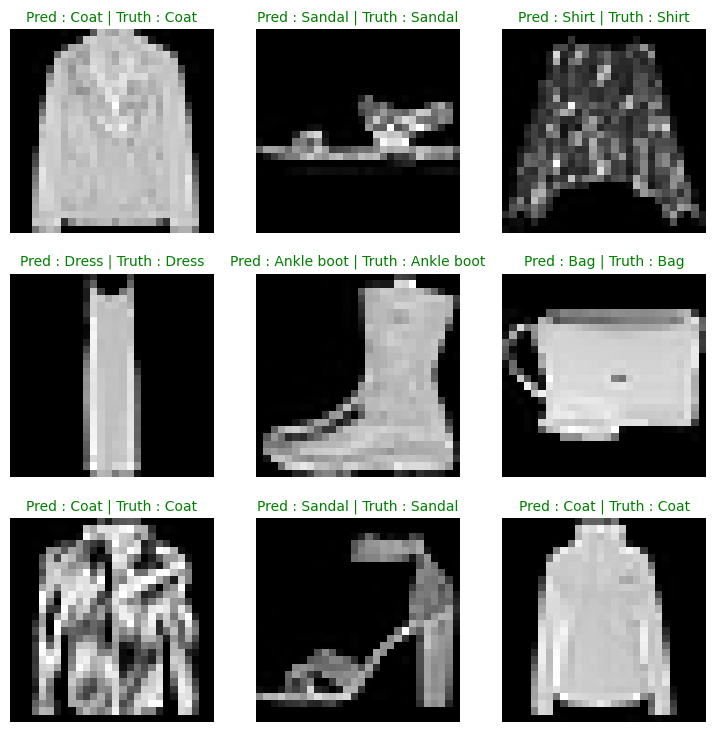

In [70]:
# plot predicitons
plt.figure(figsize = (9,9))
nrows = 3
ncols = 3
for i , sample in enumerate(test_samples):
  # create subplot
  plt.subplot(nrows, ncols , i+1)# i+1 for index and the ocunts start from 0 thats why +1

  # plot the target image
  plt.imshow(sample.squeeze() ,cmap = "gray")

  # find the prediction (in text form , e.g "sandal")
  pred_label = class_names[pred_classes[i]]

  # get the truth labl(in  text form )
  truth_label = class_names[test_labels[i]]

  # create a ttile fpor the plot
  title_text = f"Pred : {pred_label} | Truth : {truth_label}"

  # check for equality between pred and truth and chage color  of title text
  if pred_label == truth_label :
    plt.title(title_text , fontsize = 10 , c ="g") # green text if predictions same as truth
  else :
    plt.title(title_text , fontsize = 10 , c ="r")

  plt.axis(False)

# 10 .making a confusion matric for further prediction evaluation

a confusion matrix is a fantastic way of evaluating your classificatio model

1. make predicitons with our trained mdoel on the test dataset

2.  make a confision matrix 'torchmetrics.ConfusionMatrix'.
https://lightning.ai/docs/torchmetrics/stable/classification/confusion_matrix.html#id5

3. plto the confusion matrix using the 'mixtend.plotting.plot_confusion_matrix()'.

https://rasbt.github.io/mlxtend/user_guide/plotting/plot_confusion_matrix/




In [71]:
# import tqdm.auto
from tqdm.auto import tqdm

# 1. make predictions with trained model
y_preds = []
model_2.eval()
with torch.inference_mode():
  for X , y in tqdm (test_dataloader ,desc = "making predictions...."):
    # send the data and targets to target device
    X, y = X.to(device) , y.to(device)

    #do the forward pass
    y_logit  = model_2(X)

    # turn the predictions from logits. -> predictions probabilities. -> prediction labels
    y_pred = torch.softmax(y_logit.squeeze() , dim = 0).argmax(dim   =1)

    # put prediction on CPU for evaluation
    y_preds.append(y_pred.cpu())

# concatenate list of predictions into a tensor
#print(y_preds)
y_pred_tensor = torch.cat(y_preds)
#y_pred_tensor[:10]
y_pred_tensor

making predictions....:   0%|          | 0/313 [00:00<?, ?it/s]

tensor([9, 2, 1,  ..., 8, 1, 8])

In [72]:
import mlxtend

In [73]:
mlxtend.__version__

'0.23.4'

In [74]:
mlxtend.__version__.split(".")[1]

'23'

In [ ]:
# see if required packages are installeed and if not , install them..

try:
  import torchmetrics, mlxtend
  print(f" mlxtend version : {mlxtend.__version__}")
  assert int(mlxtend.__version__.split(".")[1]) >= 19 , "mlxtend version should be higher than 0.19"

except:
  !pip install torchmetrics -U mlxtend
  import torchmetrics , mlxtend
  print(f"mlxtend version: {mlxtend.__version__}")

In [78]:
import mlxtend

In [ ]:
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

# 2. setup confusion instance and cpmpare predictions to targets
confmat = ConfusionMatrix(task = "multiclass" ,num_classes = len(class_names))
confmat_tensor = confmat(preds = y_pred_tensor,
                         target =test_data.targets)

# 3. plot the confusion matrix
fig , ax  = plot_confusion_matrix(
    conf_mat = confmat_tensor.numpy() , # matplotlib likes working with numpy
    class_names  = class_names,
    figsize =(9,6)
)

In [ ]:
confmat_tensor

# 11. save and load bes performing model

In [ ]:
from pathlib import Path
# create model dictory path
MODEL_PATH = Path("model")
MODEL_PATH.mkdir(parents = True,
                 exist_ok = True )

# create model save
MODEL_NAME = "03_pytorch_computer_vision_model_2.pth"
MODEL_SAVE_PATH = MODEL_PATH /MODEL_NAME

# save the model state dict
print(f"saving model to: {MODEL_SAVE_PATH}")
torch.save(obj = model_2.state_dict(),
          f = MODEL_SAVE_PATH)


In [ ]:
model_2.state_dict()

In [ ]:
test_image.shape

In [ ]:
image_shape = [1,28,28]

In [ ]:
# create a new instance
torch.manual_seed(42)

loaded_model_2 = FashionMNISTModelV2(input_shape = 1,
                                     hidden_units = 10,
                                     output_shape =len(class_names))

# load in the save state dict()
loaded_model_2.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

# send the model to the target device

loaded_model_2.to(device)


In [ ]:
# evaluate loaded model
torch.manual_seed(42)

loaded_model_2_results = eval_model(
    model = loaded_model_2,
    data_loader = test_dataloader,
    loss_fn = loss_fn,
    accuracy_fn = accuracy_fn
)
loaded_model_2_results


In [ ]:
model_2_results

In [ ]:
# check if model results are close to eahc other

torch.isclose(torch.tensor(model_2_results["model_loss"]),
              torch.tensor(loaded_model_2_results["model_loss"]),
              atol =1e-02)
